# 05 · Bonus insights (Task 3)

**Purpose:** show what else the pipeline's structured fields make visible, for different stakeholders.  
**Decisions implemented:** D6 (three connected insights plus one described idea).  
**Inputs → outputs:** `outputs/analysis/candidates/` (written by `src/ti/analysis/candidates.py`), `outputs/stage*/` → three insight sections.

*Run from the project root or from `notebooks/`; nothing is written, and no model is called (replay mode).*

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from ti import nbhelpers as nb
nb.setup()
print("replay mode: no network, no API key, no spend")

replay mode: no network, no API key, no spend


Six candidates were tested and ranked in `docs/analysis-candidates.md`. Three are presented because they share data and form one story: **the March outage made competitors live objections and put specific
accounts at risk.** All three only exist because the pipeline turned unstructured calls into fields (theme, incident, scores, evidence quotes). Provided key moments and churn signals are used only as
*comparison data*, never as inputs. **No outcome labels exist** (no churn, no renewal results), so nothing here is validated against reality.

In [2]:
cand = nb.read_json("outputs/analysis/candidates/summary.json")
nb.md(f"Data caveat: {cand['a']['early_calls_discussing_outage']} of the {cand['a']['calls_dated_before_outage']} calls dated before {cand['a']['outage_start']} discuss the outage in the past tense, "
      "so call dates are partly inconsistent with content and date-based before/after comparisons are not used.")

Data caveat: 6 of the 34 calls dated before 2026-03-10 discuss the outage in the past tense, so call dates are partly inconsistent with content and date-based before/after comparisons are not used.

## 1. Competitive intelligence (product managers, sales leadership)

**Question:** which competitors come up, in which calls, and did that change after the outage?

In [3]:
e = cand["e"]
nb.md(f"{e['any_competitor_calls']} of 100 calls name a competitor ({e['any_competitor_by_type']}). Competitor-mentioning calls are outage-related {nb.pct(e['any_competitor_incident_share'], 0)} of the time against {nb.pct(e['base_incident_share'], 0)} for all calls.")
comp = pd.DataFrame([{"competitor": x["competitor"], "calls": x["calls"], "external / internal / support": "{external} / {internal} / {support}".format(**{k: x["by_type"].get(k, 0) for k in nb.TYPES}),
                      "outage-related": nb.pct(x["incident_flag_share"], 0), "raised by customer": x["customer_raised_mentions"], "mean call score": x["mean_call_score"]} for x in e["competitors"]])
nb.table(comp)
mon = pd.DataFrame({"calls": e["calls_by_month"], "naming a competitor": e["any_competitor_by_month"]})
mon["share"] = (mon["naming a competitor"] / mon.calls).map(lambda v: nb.pct(v, 0))
nb.table(mon.reset_index(names="month"))
top = e["competitors"][0]
nb.md("An example, in the customer's words (verbatim):")
nb.table(pd.DataFrame(top["quotes"][:2])[["date", "title", "speaker", "quote"]].assign(quote=lambda d: d.quote.map(lambda s: nb.short(s, 260))))

31 of 100 calls name a competitor ({'external': 17, 'internal': 10, 'support': 4}). Competitor-mentioning calls are outage-related 74% of the time against 42% for all calls.

competitor,calls,external / internal / support,outage-related,raised by customer,mean call score
SentinelShield,22,10 / 8 / 4,82%,18,2.95
VaultEdge,12,6 / 6 / 0,58%,7,3.42
CyberNova,8,2 / 5 / 1,62%,3,3.25
Fortiguard,3,1 / 2 / 0,33%,1,3.50


month,calls,naming a competitor,share
2026-02,26,6,23%
2026-03,36,16,44%
2026-04,38,9,24%


An example, in the customer's words (verbatim):

date,title,speaker,quote
2026-02-19,Competitive Landscape Review,Tom Bradley,"Yeah no, agreed. I got the deck you sent over this morning. Hadn't had a chance to fully go through it but I did skim the section on SentinelShield. That one stood out to me."
2026-02-19,Competitive Landscape Review,Tom Bradley,Mm. What's the — what's the pitch they're running? Like what's SentinelShield leading with?


**So what:** the *product manager* gets a ranked list of competitor capabilities customers raise, and *sales* can see that competitors became more frequent in March, alongside the outage.
**Caveat:** names came from a proper-noun scan plus a manual check, not a maintained competitor list.

## 2. Outage blast radius (engineering, support, executives)

**Question:** how far did the outage spread across accounts and call types, and what did it do to tone?

22 of 32 customer accounts (69%) had at least one outage-related call, across all three call types ({'external': 18, 'internal': 14, 'support': 10}).

type,incident_flag,n,mean call score,mean customer score
external,does not,22,4.43,4.43
external,touches outage,18,3.36,3.14
internal,does not,16,3.81,–
internal,touches outage,14,3.14,–
support,does not,20,3.28,3.15
support,touches outage,10,2.25,2.20


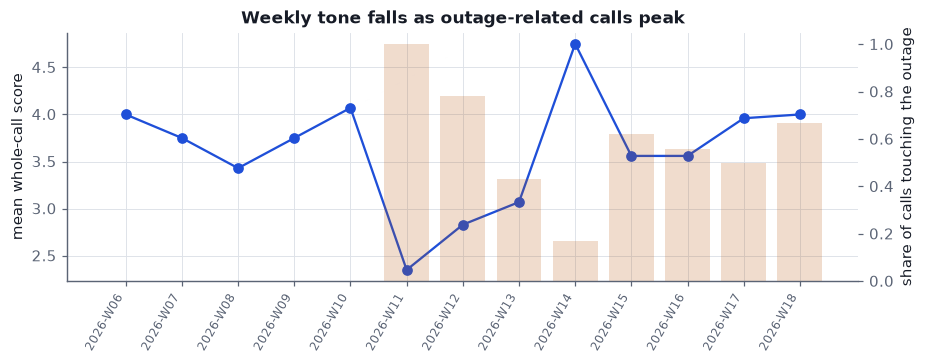

In [4]:
a = cand["a"]
nb.md(f"{a['accounts_with_incident_call']} of {a['accounts_total']} customer accounts ({nb.pct(a['accounts_with_incident_call'] / a['accounts_total'], 0)}) had at least one outage-related call, across all three call types ({a['flagged_by_type']}).")
t = pd.read_csv(ROOT / "outputs/analysis/candidates/a_incident_vs_not_by_type.csv")
t["incident_flag"] = t.incident_flag.map({True: "touches outage", False: "does not"})
nb.table(t.rename(columns={"call": "mean call score", "cust": "mean customer score"}))
wk = pd.read_csv(ROOT / "outputs/analysis/candidates/a_weekly_timeline.csv")
fig, ax = plt.subplots(figsize=(8.5, 3.4)); ax2 = ax.twinx()
ax.plot(wk.week, wk.mean_call_score, marker="o", color="#1f4fd8"); ax2.bar(wk.week, wk.incident_share, alpha=0.2, color="#b45309")
ax.set_ylabel("mean whole-call score"); ax2.set_ylabel("share of calls touching the outage"); ax2.grid(False)
ax.set_title("Weekly tone falls as outage-related calls peak"); plt.setp(ax.get_xticklabels(), rotation=60, ha="right", fontsize=8); plt.tight_layout(); plt.show()

**So what:** *executives and engineering* see the outage as a cross-team event with a measurable tone cost in every call type. **Caveat:** the incident flag is an LLM judgment, partly definitional; in the candidate's 20-call check it missed 3 and never over-flagged, so 42 is probably a floor (touches vs core), and the per-account
before/after comparison is mechanically biased (the outage call is itself the "after"), so it is deliberately **not** shown.

## 3. Churn early-warning list (sales managers)

**Question:** which external accounts should a human follow up with first?  A transparent 0 to 4 index, not a prediction.

In [5]:
b = cand["b"]
nb.md("One point each for: customer-side score of 2.5 or less; tone falling within the call; the customer raising a competitor or alternatives; the call concerning the outage. "
      f"{b['flagged_ge3']} of {b['external_calls']} external calls score 3 or more. All {b['flagged_ge3_with_provided_churn_signal']} also carry a provided churn-signal moment (an upstream AI output, comparison only); "
      f"those moments cover {b['flagged_ge3_with_provided_churn_signal']} of {b['provided_churn_signal_calls']} calls that have one.")
rk = pd.read_csv(ROOT / "outputs/analysis/candidates/b_external_calls_risk_ranking.csv")
nb.table(rk[rk.our_points >= 3][["date", "org", "title", "customer_score", "our_points", "why"]].assign(title=lambda d: d.title.map(lambda s: nb.short(s, 55))))

One point each for: customer-side score of 2.5 or less; tone falling within the call; the customer raising a competitor or alternatives; the call concerning the outage. 11 of 40 external calls score 3 or more. All 11 also carry a provided churn-signal moment (an upstream AI output, comparison only); those moments cover 11 of 18 calls that have one.

date,org,title,customer_score,our_points,why
2026-03-12,northstarpharma,Aegis / Northstar Pharma - Urgent: Detect Outage Impact,2.0,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-14,meridiancapital,Aegis / Meridian Capital - Service Reliability Discuss…,2.0,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-17,helixdata,Aegis / Helix Data - Post-Incident Review,2.0,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-19,quantumedge,Aegis / Quantum Edge - Renewal Concerns,2.0,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-26,summittrust,Aegis / Summit Trust - Platform Concerns Discussion,2.0,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-04-14,ironworkscorp,Aegis / Ironworks Corp - Vendor Comparison Discussion,2.0,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-21,novaretail,Aegis / Nova Retail Group - Renewal Discussion,2.5,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-28,ironcladfinancial,Aegis / Ironclad Financial - Account Recovery Check-in,2.5,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-04-22,brightpathcommerce,Aegis / Brightpath Commerce - Competitive Evaluation,2.5,4,customer score <= 2.5; customer raises competitor/alternatives; call concerns the outage
2026-03-24,steelpointmfg,Aegis / Steelpoint Manufacturing - Contract Review,3.0,3,customer score <= 3.0; customer raises competitor/alternatives; call concerns the outage


**So what:** a ranked follow-up list for *sales managers*, each row clickable back to a call through its evidence quote.
**Caveats:** the signals are collinear (the competitor flag fires on many calls); the top calls' tone mostly recovers by the end; there is **no churn outcome to validate against**. Present it as a list for human follow-up.

## A described idea, not built: commitment tracking (support leads, account managers)

In [6]:
dd = cand["d"]
nb.md(f"{dd['commitment_sentences']} staff promises with a time phrase (\"by Wednesday\", \"within the hour\") in {dd['calls_with_commitment']} calls. "
      f"Only {dd['with_a_later_call_same_account']} have any later call with the same account, so follow-through can barely be checked in this sample. "
      "With a real call history the same extraction would show which promises were kept; here it is an idea with a feasibility check, not a finding.")

112 staff promises with a time phrase ("by Wednesday", "within the hour") in 66 calls. Only 42 have any later call with the same account, so follow-through can barely be checked in this sample. With a real call history the same extraction would show which promises were kept; here it is an idea with a feasibility check, not a finding.

## Considered and not presented

- *Support-to-engineering loop:* repeat contacts are mostly about different issues, so "recurring issue" is thin.
- *Coaching signal:* empathy markers correlate negatively with customer score because agents apologise more to unhappy customers: confounded.